In [1]:
import os
import math
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from typing import Tuple

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

DATA_CSV = "SPY_2010_2023.csv"  # if exists, we will use it




Using device: cpu


In [2]:
import datetime as dt

try:
    import yfinance as yf
except ImportError:
    yf = None
    print("yfinance is not installed. If SPY CSV is missing, please pip install yfinance.")


def load_spy_prices() -> pd.DataFrame:
    """Load SPY daily data for 2010-01-04 to 2023-12-31.

    Priority:
    1) Local CSV file named DATA_CSV in current directory
    2) Download via yfinance (if available)
    """
    if os.path.exists(DATA_CSV):
        print(f"Loading data from {DATA_CSV}")
        df = pd.read_csv(DATA_CSV, parse_dates=["Date"])
        # Some provided CSVs have a second header row with tickers (e.g. 'SPY').
        # Drop any rows where 'Date' is missing after parsing.
        df = df.dropna(subset=["Date"]).copy()
    else:
        if yf is None:
            raise RuntimeError(
                f"{DATA_CSV} not found and yfinance is not installed. "
                "Either place the CSV in the working directory or install yfinance."
            )
        start = dt.datetime(2010, 1, 4)
        end = dt.datetime(2023, 12, 31)
        print("Downloading SPY data from yfinance ...")
        df = yf.download("SPY", start=start, end=end)
        df = df.reset_index()  # ensure Date is a column
        # yfinance may return either 'Adj Close' or just 'Close' depending on auto_adjust
        base_col = None
        if "Adj Close" in df.columns:
            base_col = "Adj Close"
        elif "AdjClose" in df.columns:
            base_col = "AdjClose"
        elif "Close" in df.columns:
            base_col = "Close"
        else:
            raise KeyError("Could not find price column among ['Adj Close', 'AdjClose', 'Close']")
        df["AdjClose"] = df[base_col]
        df.to_csv(DATA_CSV, index=False)
        print(f"Saved downloaded data to {DATA_CSV}")

    # Ensure we have a unified 'AdjClose' column regardless of CSV format
    if "AdjClose" not in df.columns:
        if "Adj Close" in df.columns:
            df.rename(columns={"Adj Close": "AdjClose"}, inplace=True)
        elif "Close" in df.columns:
            df["AdjClose"] = df["Close"]
        else:
            raise KeyError("'[AdjClose]' not in index and no fallback column like 'Close' found")

    df = df.sort_values("Date")
    return df[["Date", "AdjClose"]]


def compute_log_returns(df: pd.DataFrame) -> pd.DataFrame:
    prices = df["AdjClose"].astype(float)
    log_prices = np.log(prices)
    log_ret = log_prices.diff().dropna()
    out = pd.DataFrame({
        "Date": df["Date"].iloc[1:].values,
        "LogReturn": log_ret.values,
    })
    return out


df_prices = load_spy_prices()
df_returns = compute_log_returns(df_prices)
print(df_returns.head())
print("Number of log-return points:", len(df_returns))


/tmp/ipython-input-524876416.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("SPY", start=start, end=end)
[*********************100%***********************]  1 of 1 completed


Saved downloaded data to SPY_2010_2023.csv
        Date  LogReturn
0 2010-01-05   0.002644
1 2010-01-06   0.000704
2 2010-01-07   0.004212
3 2010-01-08   0.003322
4 2010-01-11   0.001396
Number of log-return points: 3521


In [3]:
SEQ_LEN = 64

class ReturnSeriesDataset(Dataset):
    def __init__(self, returns: np.ndarray, seq_len: int = SEQ_LEN):
        self.seq_len = seq_len
        self.returns = returns.astype(np.float32)
        self.mean = self.returns.mean()
        self.std = self.returns.std() + 1e-8
        self.norm_returns = (self.returns - self.mean) / self.std
        self.sequences = self._build_sequences(self.norm_returns)

    def _build_sequences(self, arr: np.ndarray) -> np.ndarray:
        num = len(arr) - self.seq_len + 1
        seqs = np.stack([arr[i : i + self.seq_len] for i in range(num)], axis=0)
        return seqs

    def __len__(self) -> int:
        return self.sequences.shape[0]

    def __getitem__(self, idx: int) -> torch.Tensor:
        return torch.from_numpy(self.sequences[idx])


all_returns = df_returns["LogReturn"].values

# chronological split 90% train, 10% test on the *time dimension*
split_idx = int(0.9 * len(all_returns))
train_ret = all_returns[:split_idx]
test_ret = all_returns[split_idx - SEQ_LEN + 1 :]  # small overlap so we can form sequences

train_dataset = ReturnSeriesDataset(train_ret, SEQ_LEN)
# for test, reuse train normalisation to be fair

class ReturnSeriesTestDataset(Dataset):
    def __init__(self, returns: np.ndarray, seq_len: int, mean: float, std: float):
        self.seq_len = seq_len
        self.mean = mean
        self.std = std
        norm = (returns.astype(np.float32) - mean) / (std + 1e-8)
        num = len(norm) - seq_len + 1
        self.sequences = np.stack([norm[i : i + seq_len] for i in range(num)], axis=0)

    def __len__(self):
        return self.sequences.shape[0]

    def __getitem__(self, idx):
        return torch.from_numpy(self.sequences[idx])


test_dataset = ReturnSeriesTestDataset(test_ret, SEQ_LEN, train_dataset.mean, train_dataset.std)

print("Train sequences:", len(train_dataset), "Test sequences:", len(test_dataset))



Train sequences: 3105 Test sequences: 353


Epoch 001: train_loss=1.993346, val_loss=2.090108
Epoch 002: train_loss=1.995942, val_loss=2.110403
Epoch 003: train_loss=1.979732, val_loss=2.069606
Epoch 004: train_loss=1.989885, val_loss=2.088982
Epoch 005: train_loss=1.982416, val_loss=2.086308
Epoch 006: train_loss=1.987590, val_loss=2.073036
Epoch 007: train_loss=1.988089, val_loss=2.086086
Epoch 008: train_loss=1.978859, val_loss=2.091280
Epoch 009: train_loss=1.979116, val_loss=2.083514
Epoch 010: train_loss=1.972500, val_loss=2.084413
Epoch 011: train_loss=1.981428, val_loss=2.071609
Epoch 012: train_loss=1.979380, val_loss=2.059068
Epoch 013: train_loss=1.974402, val_loss=2.062549
Epoch 014: train_loss=1.970329, val_loss=2.084478
Epoch 015: train_loss=1.971374, val_loss=2.095874
Epoch 016: train_loss=1.968195, val_loss=2.106712
Epoch 017: train_loss=1.966824, val_loss=2.115281
Epoch 018: train_loss=1.965187, val_loss=2.081604
Epoch 019: train_loss=1.967866, val_loss=2.099645
Epoch 020: train_loss=1.948826, val_loss=2.082897


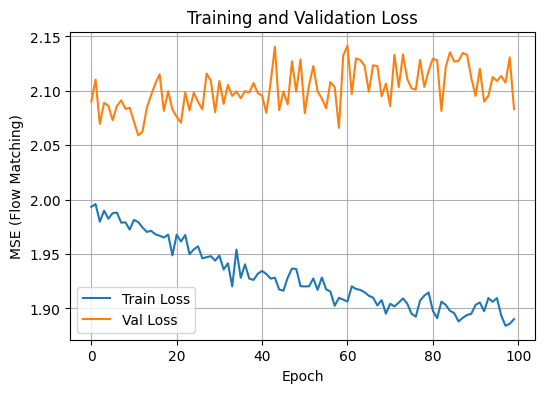

In [4]:
BATCH_SIZE = 512
LR = 2e-4
EPOCHS = 100

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)


class VectorField(nn.Module):
    """Simple MLP that predicts v_theta(x_t, t).

    We treat each sequence as a vector of length SEQ_LEN.
    Time t is a scalar in [0, 1] and is concatenated to the input.
    """

    def __init__(self, dim: int):
        super().__init__()
        hidden = 256
        self.net = nn.Sequential(
            nn.Linear(dim + 1, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, dim),
        )

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # x: (B, D), t: (B, 1)
        xt = torch.cat([x, t], dim=-1)
        return self.net(xt)


model = VectorField(SEQ_LEN).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)


def train_epoch(epoch: int):
    model.train()
    total_loss = 0.0
    n = 0
    for batch in train_loader:
        batch = batch.to(DEVICE)  # shape (B, L)
        B = batch.shape[0]
        # base sample x0 ~ N(0, I)
        x0 = torch.randn_like(batch)
        x1 = batch
        # sample t ~ Uniform(0, 1)
        t = torch.rand(B, 1, device=DEVICE)
        # linear interpolant
        xt = (1.0 - t) * x0 + t * x1
        target_v = x1 - x0  # ideal vector field for linear flow

        pred_v = model(xt, t)
        loss = ((pred_v - target_v) ** 2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * B
        n += B
    return total_loss / n


def eval_epoch():
    model.eval()
    total_loss = 0.0
    n = 0
    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(DEVICE)
            B = batch.shape[0]
            x0 = torch.randn_like(batch)
            x1 = batch
            t = torch.rand(B, 1, device=DEVICE)
            xt = (1.0 - t) * x0 + t * x1
            target_v = x1 - x0
            pred_v = model(xt, t)
            loss = ((pred_v - target_v) ** 2).mean()
            total_loss += loss.item() * B
            n += B
    return total_loss / n


train_losses = []
val_losses = []

for epoch in range(1, EPOCHS + 1):
    train_loss = train_epoch(epoch)
    val_loss = eval_epoch()
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f"Epoch {epoch:03d}: train_loss={train_loss:.6f}, val_loss={val_loss:.6f}")


plt.figure(figsize=(6, 4))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (Flow Matching)")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()



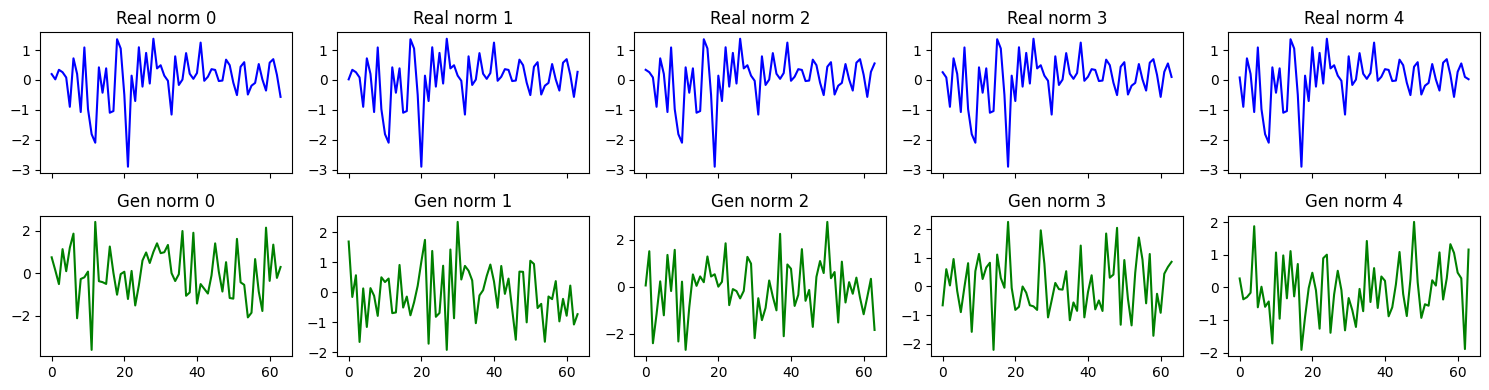

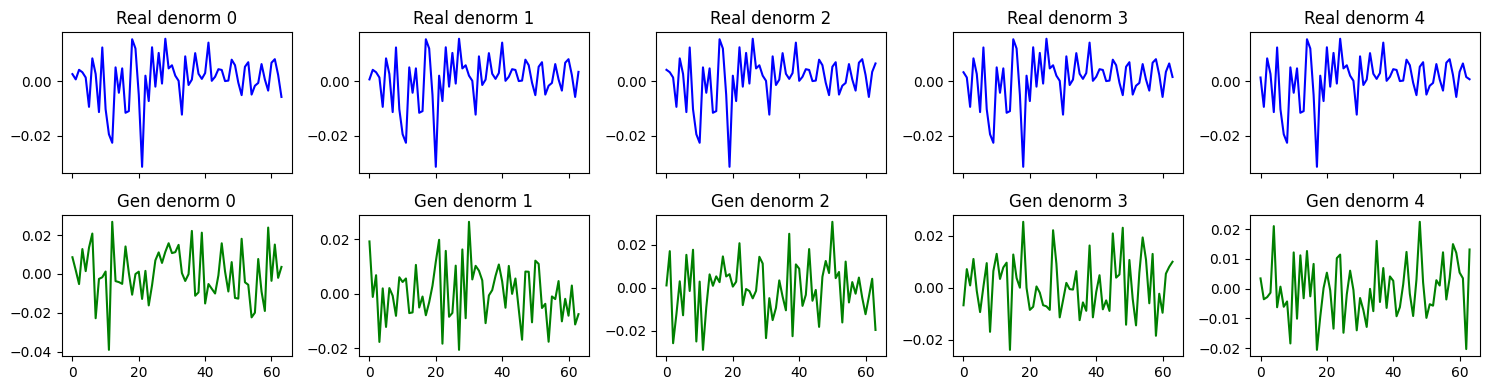

In [5]:
@torch.no_grad()
def sample_sequences(num_samples: int, steps: int = 100) -> torch.Tensor:
    """Generate synthetic sequences by integrating dx/dt = v_theta(x, t).

    Uses simple Euler integration from t=0 to t=1.
    Returns tensor of shape (num_samples, SEQ_LEN) in *normalized* space.
    """
    model.eval()
    x = torch.randn(num_samples, SEQ_LEN, device=DEVICE)
    t0, t1 = 0.0, 1.0
    dt_step = (t1 - t0) / steps
    t = torch.full((num_samples, 1), t0, device=DEVICE)
    for _ in range(steps):
        v = model(x, t)
        x = x + dt_step * v
        t = t + dt_step
    return x.cpu()


def denormalize_sequences(seqs_norm: torch.Tensor, mean: float, std: float) -> torch.Tensor:
    return seqs_norm * std + mean


# Example sampling + plotting a few trajectories
num_show = 5
samples_norm = sample_sequences(num_show, steps=200)
samples_denorm = denormalize_sequences(samples_norm, train_dataset.mean, train_dataset.std)

real_example = train_dataset[0: num_show].numpy()
real_denorm = denormalize_sequences(torch.from_numpy(real_example), train_dataset.mean, train_dataset.std)

fig, axes = plt.subplots(2, num_show, figsize=(3 * num_show, 4), sharex=True)
for i in range(num_show):
    axes[0, i].plot(real_example[i], color="blue")
    axes[0, i].set_title(f"Real norm {i}")
    axes[1, i].plot(samples_norm[i].numpy(), color="green")
    axes[1, i].set_title(f"Gen norm {i}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, num_show, figsize=(3 * num_show, 4), sharex=True)
for i in range(num_show):
    axes[0, i].plot(real_denorm[i].numpy(), color="blue")
    axes[0, i].set_title(f"Real denorm {i}")
    axes[1, i].plot(samples_denorm[i].numpy(), color="green")
    axes[1, i].set_title(f"Gen denorm {i}")
plt.tight_layout()
plt.show()



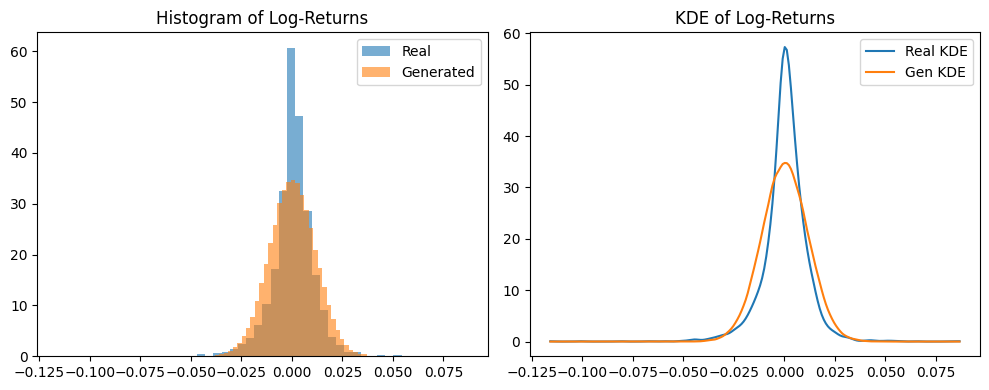

Real   mean/var/vol: 0.00048184227232469026 0.00011982732393234647 0.01094656676462289
Gen    mean/var/vol: 0.0002677556767594069 0.00013279338600113988 0.011523601599037647


In [6]:
# === Distribution comparison: histograms and KDE-like smoothed histograms ===

from scipy.stats import gaussian_kde


def flatten_sequences(arr: np.ndarray) -> np.ndarray:
    return arr.reshape(-1)


# collect a reasonably large set of generated sequences
num_gen = 2000
samples_norm_all = sample_sequences(num_gen, steps=200)
samples_denorm_all = denormalize_sequences(samples_norm_all, train_dataset.mean, train_dataset.std)

gen_returns = samples_denorm_all.numpy().reshape(-1)
real_returns = all_returns  # original log-returns (denormalized by definition)


fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(real_returns, bins=50, density=True, alpha=0.6, label="Real")
ax[0].hist(gen_returns, bins=50, density=True, alpha=0.6, label="Generated")
ax[0].set_title("Histogram of Log-Returns")
ax[0].legend()

# KDE
real_kde = gaussian_kde(real_returns)
gen_kde = gaussian_kde(gen_returns)
x_grid = np.linspace(min(real_returns.min(), gen_returns.min()), max(real_returns.max(), gen_returns.max()), 200)
ax[1].plot(x_grid, real_kde(x_grid), label="Real KDE")
ax[1].plot(x_grid, gen_kde(x_grid), label="Gen KDE")
ax[1].set_title("KDE of Log-Returns")
ax[1].legend()

plt.tight_layout()
plt.show()

# === Basic statistics ===

real_mean = float(real_returns.mean())
real_var = float(real_returns.var())
real_vol = float(real_returns.std())

gen_mean = float(gen_returns.mean())
gen_var = float(gen_returns.var())
gen_vol = float(gen_returns.std())

print("Real   mean/var/vol:", real_mean, real_var, real_vol)
print("Gen    mean/var/vol:", gen_mean, gen_var, gen_vol)



Sliced Wasserstein Distance (SWD): 0.0024563690251102606
Autocorrelation MSE: 0.0031134113669395447
Autocorrelation mean absolute diff: 0.04185113310813904


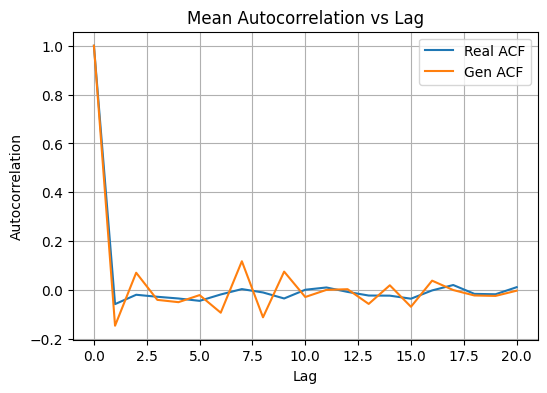

In [7]:
# === Advanced metrics: SWD and autocorrelation metrics ===

from scipy.stats import wasserstein_distance


def sliced_wasserstein_distance(real_seqs: np.ndarray, gen_seqs: np.ndarray, n_projections: int = 100) -> float:
    """Compute Sliced Wasserstein Distance between two sets of sequences.

    Projects sequences onto random 1D directions and averages 1D Wasserstein-1.
    real_seqs, gen_seqs: (N, L)
    """
    assert real_seqs.shape[1] == gen_seqs.shape[1]
    L = real_seqs.shape[1]
    swd_vals = []
    for _ in range(n_projections):
        direction = np.random.randn(L)
        direction /= np.linalg.norm(direction) + 1e-8
        proj_real = real_seqs @ direction
        proj_gen = gen_seqs @ direction
        swd_vals.append(wasserstein_distance(proj_real, proj_gen))
    return float(np.mean(swd_vals))


def autocorrelation(x: np.ndarray, max_lag: int) -> np.ndarray:
    x = x - x.mean()
    result = np.correlate(x, x, mode="full")
    acf = result[result.size // 2 : result.size // 2 + max_lag + 1]
    acf /= acf[0] + 1e-8
    return acf


def compute_autocorr_metrics(real_seqs: np.ndarray, gen_seqs: np.ndarray, max_lag: int = 20):
    acf_real = np.array([autocorrelation(s, max_lag) for s in real_seqs])
    acf_gen = np.array([autocorrelation(s, max_lag) for s in gen_seqs])

    mean_acf_real = acf_real.mean(axis=0)
    mean_acf_gen = acf_gen.mean(axis=0)

    mse = float(((mean_acf_real - mean_acf_gen) ** 2).mean())
    mean_diff = float(np.abs(mean_acf_real - mean_acf_gen).mean())
    return mse, mean_diff, mean_acf_real, mean_acf_gen


# Prepare comparable real/gen sets in *denormalized* space
num_eval = min(2000, len(train_dataset))
real_seq_norm = np.stack([train_dataset[i].numpy() for i in range(num_eval)], axis=0)
real_seq = denormalize_sequences(torch.from_numpy(real_seq_norm), train_dataset.mean, train_dataset.std).numpy()

gen_seq_norm = sample_sequences(num_eval, steps=200).numpy()
gen_seq = denormalize_sequences(torch.from_numpy(gen_seq_norm), train_dataset.mean, train_dataset.std).numpy()

swd_val = sliced_wasserstein_distance(real_seq, gen_seq, n_projections=100)
print("Sliced Wasserstein Distance (SWD):", swd_val)

auto_mse, auto_mean_diff, mean_acf_real, mean_acf_gen = compute_autocorr_metrics(real_seq, gen_seq, max_lag=20)
print("Autocorrelation MSE:", auto_mse)
print("Autocorrelation mean absolute diff:", auto_mean_diff)

lags = np.arange(len(mean_acf_real))
plt.figure(figsize=(6, 4))
plt.plot(lags, mean_acf_real, label="Real ACF")
plt.plot(lags, mean_acf_gen, label="Gen ACF")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.title("Mean Autocorrelation vs Lag")
plt.legend()
plt.grid(True)
plt.show()

